In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import sklearn.preprocessing

In [5]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

In [6]:
adult_income = fetch_ucirepo(id=2)

In [7]:
df = adult_income.data.original.copy()

In [8]:
df.sample(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
3995,27,Private,125298,Some-college,10,Never-married,Adm-clerical,Unmarried,White,Female,0,0,50,United-States,<=50K
47255,24,Self-emp-not-inc,151818,HS-grad,9,Never-married,Craft-repair,Not-in-family,White,Male,0,0,35,United-States,<=50K.
14632,20,Local-gov,247794,Assoc-voc,11,Never-married,Adm-clerical,Own-child,White,Female,0,0,35,United-States,<=50K
38393,51,Private,63081,Assoc-acdm,12,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,0,40,United-States,>50K.
25143,50,Local-gov,96062,HS-grad,9,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,<=50K


In [9]:
df.shape

(48842, 15)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [11]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [12]:
df = df.replace("?", pd.NA)

In [13]:
df.isna().sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

In [14]:
df.isna().mean()*100

age               0.000000
workclass         5.730724
fnlwgt            0.000000
education         0.000000
education-num     0.000000
marital-status    0.000000
occupation        5.751198
relationship      0.000000
race              0.000000
sex               0.000000
capital-gain      0.000000
capital-loss      0.000000
hours-per-week    0.000000
native-country    1.754637
income            0.000000
dtype: float64

In [15]:
df['workclass'].value_counts()

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

In [16]:
df['occupation'].value_counts()

occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                5504
Other-service        4923
Machine-op-inspct    3022
Transport-moving     2355
Handlers-cleaners    2072
Farming-fishing      1490
Tech-support         1446
Protective-serv       983
Priv-house-serv       242
Armed-Forces           15
Name: count, dtype: int64

In [17]:
df['native-country'].value_counts()

native-country
United-States                 43832
Mexico                          951
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru                             46
Ecuador      

In [18]:
df = df.fillna('Unknown')

In [19]:
df.sample(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
26754,42,Self-emp-not-inc,101709,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,Asian-Pac-Islander,Male,2885,0,40,United-States,<=50K
2313,31,Local-gov,151726,Assoc-acdm,12,Never-married,Adm-clerical,Own-child,Amer-Indian-Eskimo,Female,0,0,40,United-States,<=50K
18558,31,Private,38158,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,0,0,40,United-States,<=50K
15232,59,Private,175942,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,45,United-States,>50K
37429,40,Self-emp-inc,253060,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,55,United-States,>50K.
43932,26,Private,29488,Prof-school,15,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,40,United-States,>50K.
17768,37,Private,178948,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,45,United-States,<=50K
25246,54,Self-emp-not-inc,36327,7th-8th,4,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,50,United-States,<=50K
23710,20,Private,205975,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Female,0,0,20,United-States,<=50K
10124,80,Self-emp-not-inc,34340,7th-8th,4,Widowed,Farming-fishing,Not-in-family,White,Male,0,0,35,United-States,<=50K


In [20]:
df['race'].value_counts()

race
White                 41762
Black                  4685
Asian-Pac-Islander     1519
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64

In [21]:
df[df["capital-gain"] == 99999]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
1246,54,Self-emp-inc,166459,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,60,United-States,>50K
1368,52,Private,152234,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,99999,0,40,Japan,>50K
1482,53,Self-emp-inc,263925,HS-grad,9,Married-civ-spouse,Sales,Husband,White,Male,99999,0,40,United-States,>50K
1528,52,Private,118025,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,50,United-States,>50K
1616,46,Private,370119,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,60,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47739,32,Self-emp-inc,225053,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,60,United-States,>50K.
48582,61,Self-emp-not-inc,151369,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,30,United-States,>50K.
48591,36,Private,224566,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,99999,0,45,United-States,>50K.
48598,42,Private,32878,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,42,United-States,>50K.


In [22]:
categorical_cols = ['race', 'marital-status', 'occupation', 'relationship', 'workclass', 'native-country']
to_drop = ['education']
ordinal_cols = ['education-num']
continuous_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'fnlwgt']
binary_cols = ['sex', 'income']

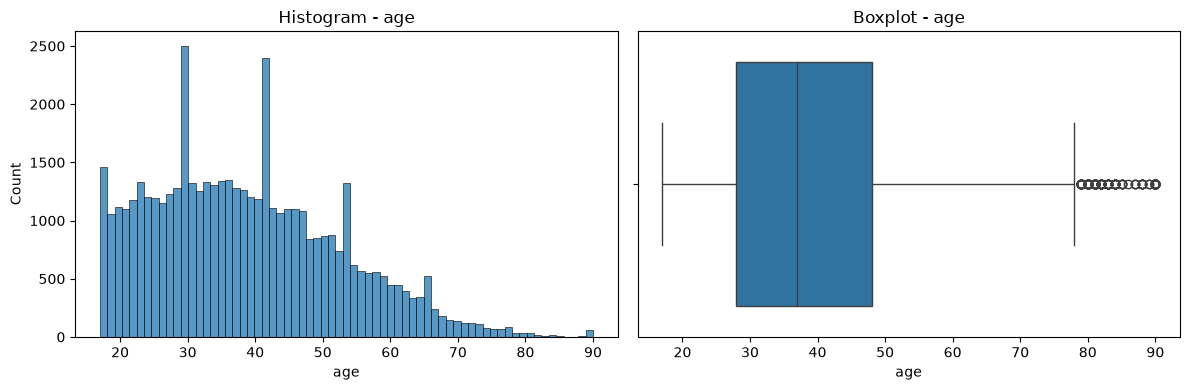

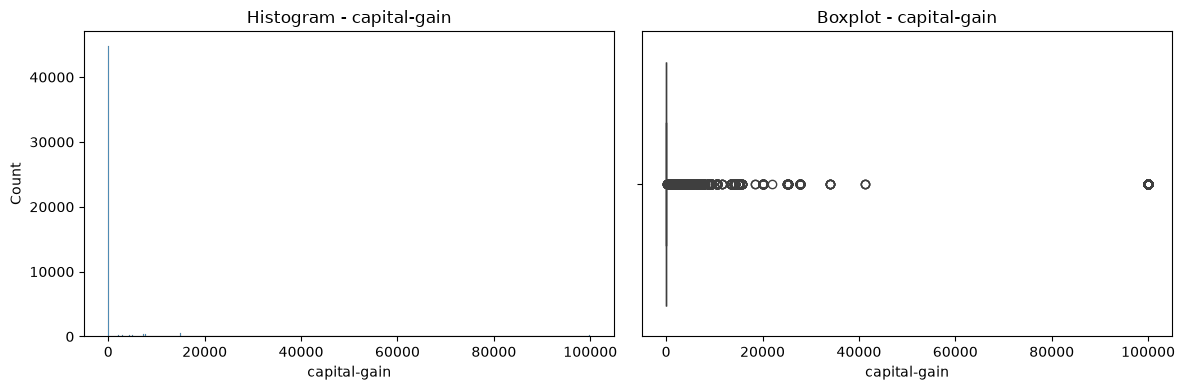

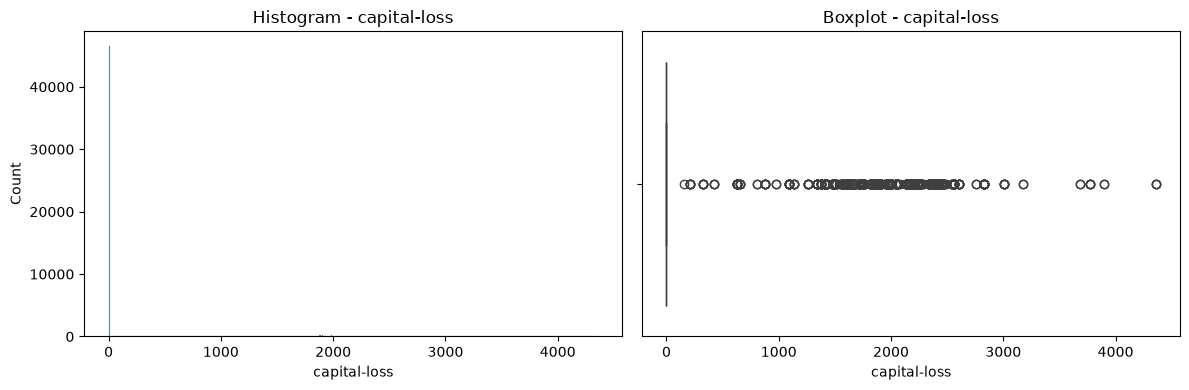

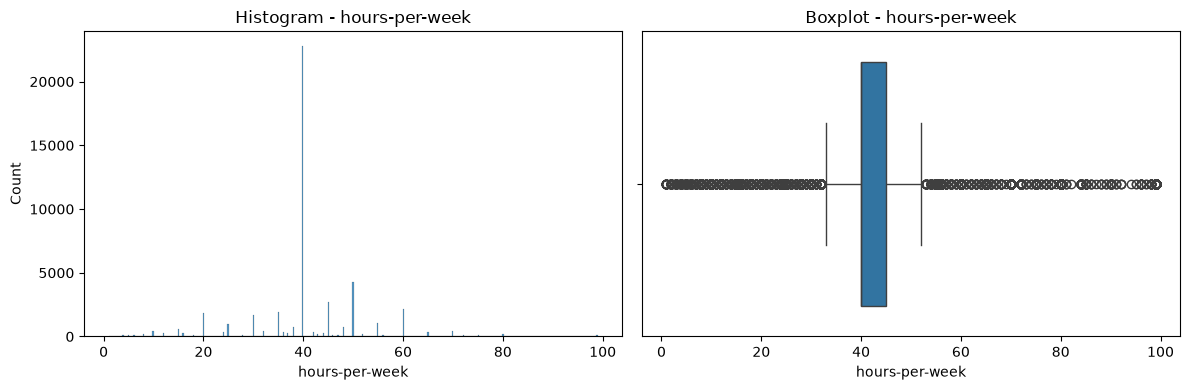

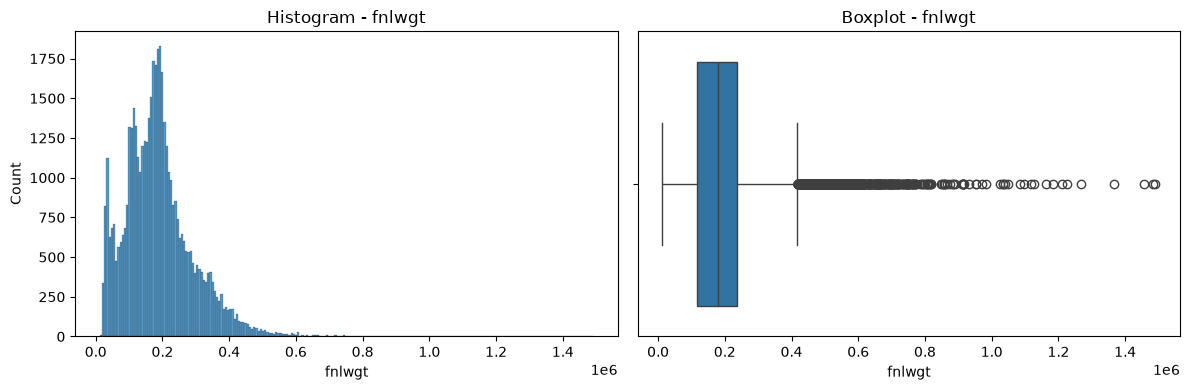

In [23]:
for col in continuous_cols:
    fig, ax = plt.subplots(1,2 , figsize=(12,4))
    sns.histplot(df[col], ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_title(f'Boxplot - {col}')

    plt.tight_layout()
    plt.show()

In [24]:
df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

In [25]:
df.shape

(48842, 93)

In [26]:
df["sex"] = df["sex"].map({"Male": 1, "Female": 0})
df["income"] = df["income"].str.rstrip(".").map({"<=50K": 0, ">50K": 1})

In [27]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
sex,48842.0,0.668482,0.470764,0.0,0.0,1.0,1.0,1.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
...,...,...,...,...,...,...,...,...
native-country_Trinadad&Tobago,48842.0,0.000553,0.023506,0.0,0.0,0.0,0.0,1.0
native-country_United-States,48842.0,0.897424,0.303407,0.0,1.0,1.0,1.0,1.0
native-country_Unknown,48842.0,0.017546,0.131297,0.0,0.0,0.0,0.0,1.0
native-country_Vietnam,48842.0,0.001761,0.041925,0.0,0.0,0.0,0.0,1.0


In [28]:
cap_cols = ['capital-gain', 'capital-loss']
for col in cap_cols:
    df[col] = np.log1p(df[col])

In [29]:
upper_fnlwgt = df["fnlwgt"].quantile(0.99)
df["fnlwgt"] = df["fnlwgt"].clip(upper=upper_fnlwgt)

In [30]:
zscore_cols = ['age', 'fnlwgt', 'education-num', 'hours-per-week']
scaler = sklearn.preprocessing.StandardScaler()
df[zscore_cols] = scaler.fit_transform(df[zscore_cols])

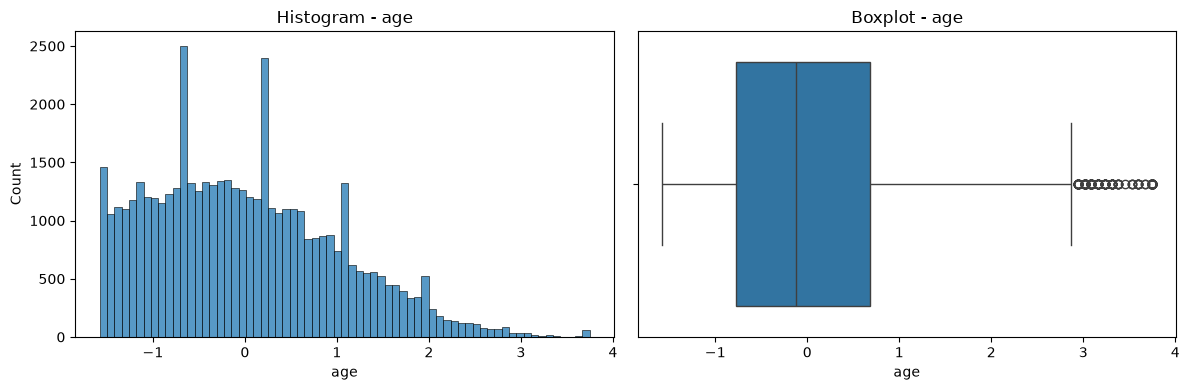

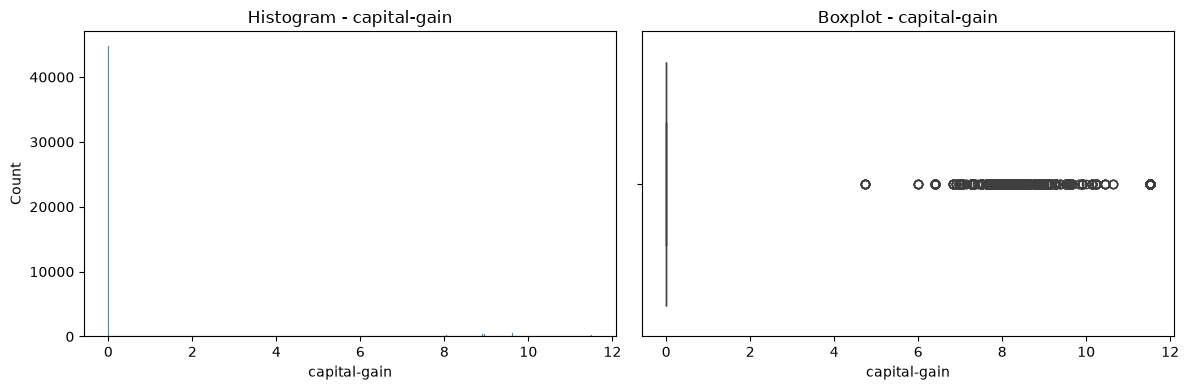

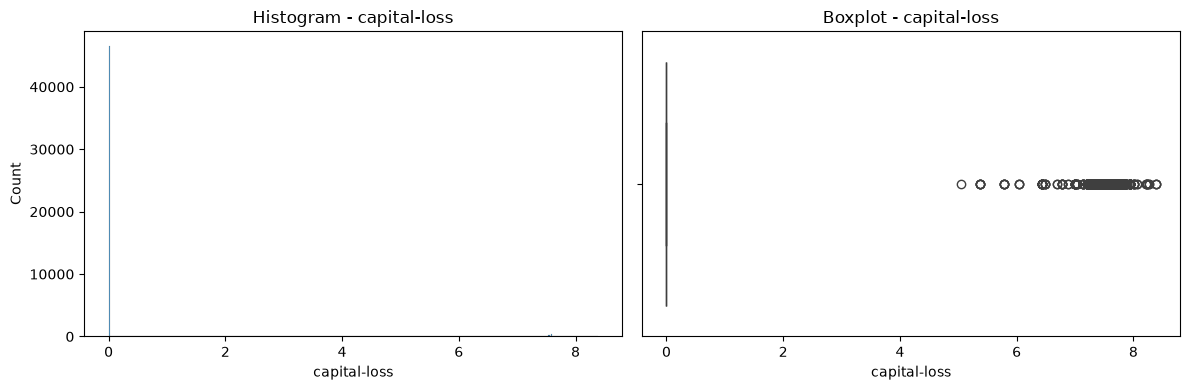

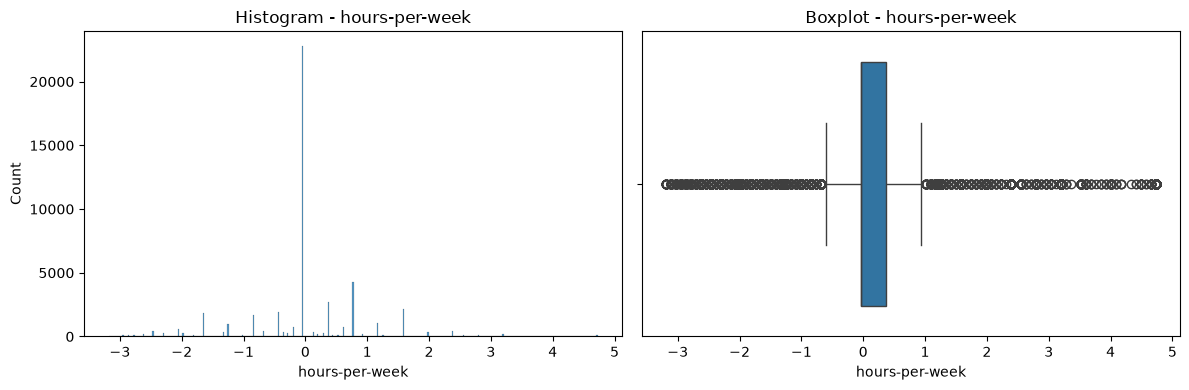

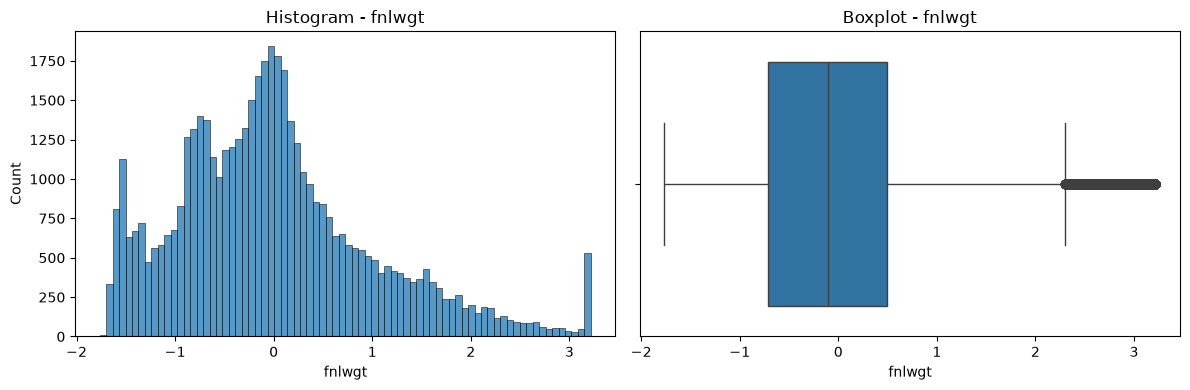

In [31]:
for col in continuous_cols:
    fig, ax = plt.subplots(1,2 , figsize=(12,4))
    sns.histplot(df[col], ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_title(f'Boxplot - {col}')

    plt.tight_layout()
    plt.show()

In [32]:
df['age_groups'] = pd.cut(
    df['age'],
    bins = [0, 25, 35, 50, 65, 100],
    labels = ['Young', 'Early Career', 'Mid-career', 'Senior', 'Retired']
)

df['work_hours_group'] = pd.cut(
    df['hours-per-week'],
    bins = [0, 34, 40, 60, 100],
    labels=["Part-Time", "Full-Time", "Overtime", "Heavy-Overtime"]    
)

df["capital_gain_level"] = pd.cut(
    df["capital-gain"],
    bins=[-1, 0, 10000, 100000],
    labels=["None", "Moderate", "High"]
)

In [33]:
df.shape

(48842, 96)

In [34]:
df_cor = df.copy()

In [35]:
num_cols = continuous_cols + ordinal_cols + binary_cols

In [36]:
corr_matrix = df_cor[num_cols].corr(method = 'pearson')

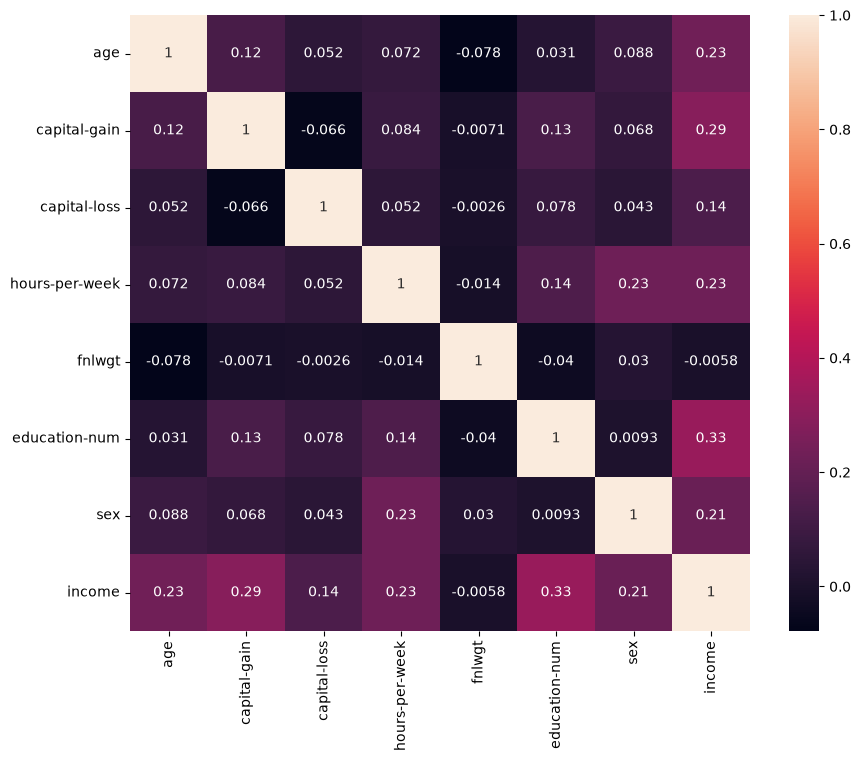

In [37]:
plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
)
plt.show()